In [1]:
import coolbox
from coolbox.api import *

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
# plt.rcdefaults() 
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from generic_plotting_functions import *

import pandas as pd
import os
import numpy as np

from load_modisco import *
import json
from domino.utils.tools import seq_from_df

import pysam

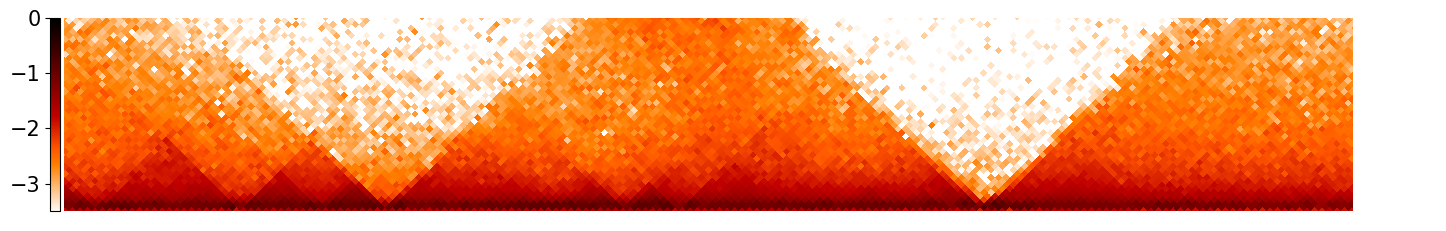

chr2R:9964319-9998795


In [2]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
RESOLUTION=200
NUM_MERGED=11

chrom, start, end = "chr2R", 9979319, 9980795

HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.3, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3.5, 
    grid=False,
)

frame = [
    # Map
    coolbox.api.HiCMat(f"{MCOOL_DATA_DIR}/new_nc14_embryo_merged_all_11.mcool", **HIC_KWARGS),
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),

]
from functools import reduce

frame = reduce(lambda x, y: x + y, frame)
fig = frame.plot(f"{chrom}:{start-15000}-{end + 18_000}")
fig.set(facecolor="white")
# fig.savefig("plots/eve_locus.pdf", format="pdf")
display(fig)

print(f"{chrom}:{start-15000}-{end + 18_000}")

In [3]:
from tangermeme.tools.fimo import fimo
from tangermeme.io import read_meme
from tangermeme.seqlet import recursive_seqlets
from tangermeme.annotate import annotate_seqlets
from tangermeme.plot import plot_logo

model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

DNA_context_bin_width=16
DNA_context_length = 200*DNA_context_bin_width

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

def add_residual_column(df):
    df['residual'] = df['demeaned_ins_score_1'] - df['pred']
    df['abs_residual'] = (df['demeaned_ins_score_1'] - df['pred']).abs()
    
for df in [TRAIN_df, VAL_df, TEST_df]:
    df = add_residual_column(df)

genome_path = '/scratch/gpfs/PRITYKIN/brendan/deeplearning-microc/data/dm6.fa'
genome_fasta = pysam.FastaFile(genome_path)

strong_bound_test_df = TEST_df.query('demeaned_ins_score_1 < -1 and boundary == 1')
strong_bound_test_df.sort_values('abs_residual', inplace=True)
strong_bound_test_df.reset_index(drop=True, inplace=True)
X = seq_from_df(genome_fasta, strong_bound_test_df, DNA_context_length)

X_attr = np.load('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/numpy_arrs/windowed_attributions.bound_score_gt_1.npy')

In [4]:
all_nc14_bounds = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_nc14_boundaries_df.bound_score_gt_1.csv')

# nhomie and homie attribution

In [5]:
nhomie_chrom, nhomie_start, nhomie_end = "chr2R", 9972801, 9973000 # NHOMIE
nhomie_row = all_nc14_bounds.query('chrom == @nhomie_chrom and start == @nhomie_start')
nhomie_row

,chrom,start,end,ins_score_1,copy_index_1,ins_score_2,copy_index_2,boundary,demeaned_ins_score_1,demeaned_ins_score_2,direction,pred,bound_score,bucket,cp190,prop_nan,has_stripe_at_bound
13890,chr2R,9972801,9973000,-1.280146,167433,-2.10757,167433,1,-1.733527,-2.270921,+,-1.112375,2.772669,"(2.7, 2.8]",130.948764,0.0,False
13891,chr2R,9972801,9973000,-1.280146,167433,-2.10757,167433,1,-1.733527,-2.270921,-,-1.063948,2.772669,"(2.7, 2.8]",130.948764,0.0,False


In [6]:
homie_chrom, homie_start, homie_end = "chr2R", 9988801, 9989000 # HOMIE
homie_row = all_nc14_bounds.query('chrom == @homie_chrom and start == @homie_start')
homie_row

,chrom,start,end,ins_score_1,copy_index_1,ins_score_2,copy_index_2,boundary,demeaned_ins_score_1,demeaned_ins_score_2,direction,pred,bound_score,bucket,cp190,prop_nan,has_stripe_at_bound
13896,chr2R,9988801,9989000,-1.187156,167513,-1.815669,167513,1,-1.583615,-1.960026,+,-0.494906,2.901843,"(2.9, 3.0]",98.078526,0.049132,False
13897,chr2R,9988801,9989000,-1.187156,167513,-1.815669,167513,1,-1.583615,-1.960026,-,-0.756091,2.901843,"(2.9, 3.0]",98.078526,0.049132,False


In [7]:
def get_motif_hits(idx):
    meme_file = "/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu//JASPAR2024_CORE_insects_non-redundant_pfms_meme.txt"
    motifs = read_meme(meme_file)
    motifs_of_interest = [
        'su(Hw)', 
        'CG4854',
        # 'pita'
    ]
    
    motifs_dict = dict()
    for k in motifs:
        if k.split(' ')[1] in motifs_of_interest:
            motifs_dict[k] = motifs[k]
        
    hits = fimo(motifs_dict, X[idx].unsqueeze(0), dim=1) # both directions
    
    # drop duplicates for palindromic motifs (e.g., BEAF-32)
    for df in hits: 
        df.drop_duplicates(subset=['motif_idx', 'sequence_name', 'start', 'end'], inplace=True)
        
    hits_ = pd.concat(hits) # get all motif hits 
    len(hits)
    all_hits = pd.concat(hits)
    return all_hits.query('start >= 3000 and end <= 3600')

nhomie_hits = get_motif_hits(144)
homie_hits = get_motif_hits(193)

In [8]:
nhomie_hits

,motif_name,motif_idx,sequence_name,start,end,strand,score,p-value
3,MA0533.1 su(Hw),0,0,3293,3314,-,23.517191,3.561127e-09
4,MA2299.1 CG4854,1,0,3204,3212,-,13.697434,3.051758e-05


In [9]:
homie_hits

,motif_name,motif_idx,sequence_name,start,end,strand,score,p-value
3,MA0533.1 su(Hw),0,0,3335,3356,+,24.408232,1.339458e-09
8,MA2299.1 CG4854,1,0,3470,3478,-,13.697434,3.051758e-05


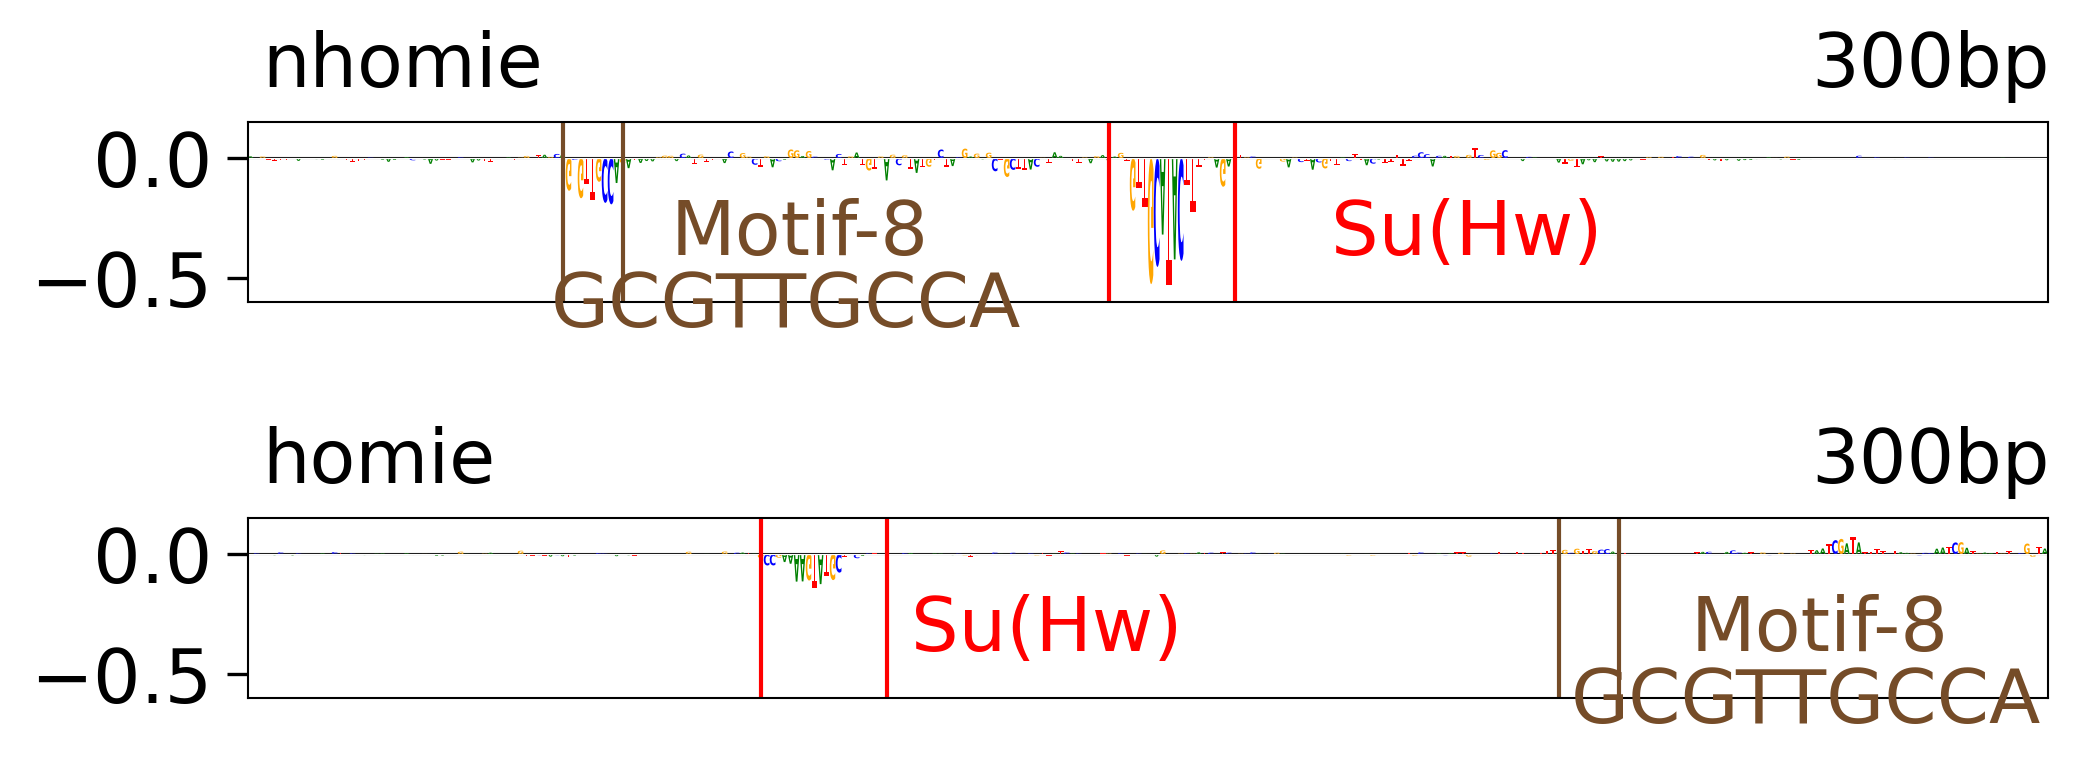

In [10]:
flanking_context=50
nhomie_start = 150
nhomie_end = 450

homie_start = 250
homie_end = 550

nhomie_attr = X_attr[13890][:,nhomie_start:nhomie_end]
homie_attr = X_attr[13896][:,homie_start:homie_end]

fig, axs = init_subplots_exact(2,2,dpi=300, y_ratios=[0.15, 0.15], x_ratios=[1.5], yspace=2.2)
ax = axs[0]
plt.sca(axs[0])
logo = plot_logo(nhomie_attr, ax=ax)
ax.axhline(0, color='w', linewidth=0.3)  # Alternatively, make the line white
ax.axvline(nhomie_hits.query('motif_name == "MA0533.1 su(Hw)"').start.iloc[0]-3300+150, color='#ff0000', linewidth=1)  # Alternatively, make the line white
ax.axvline(nhomie_hits.query('motif_name == "MA0533.1 su(Hw)"').end.iloc[0]-3300+150, color='#ff0000', linewidth=1)  # Alternatively, make the line white
ax.axvline(nhomie_hits.query('motif_name == "MA2299.1 CG4854"').start.iloc[0]-3300+150-2, color='#754c28', linewidth=1)  # Alternatively, make the line white
ax.axvline(nhomie_hits.query('motif_name == "MA2299.1 CG4854"').end.iloc[0]-3300+150, color='#754c28', linewidth=1)  # Alternatively, make the line white
ax.grid(False)
ax.set_xticks([])
ax.set_xticklabels([])
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed
ax.text(70, -0.4, 'Motif-8', color='#754c28')
ax.text(180, -0.4, 'Su(Hw)', color='#ff0000')
ax.text(260, 0.3, '300bp', color='black')
ax.text(2, 0.3, 'nhomie', color='black')
ax.text(50, -0.7, 'GCGTTGCCA', color='#754c28')


for spine in ax.spines.values():
    spine.set_visible(True)  
    spine.set_linewidth(0.5)  
    spine.set_edgecolor("black")  

plt.ylim([-0.6, 0.15])

ax = axs[1]
plt.sca(axs[1])
logo = plot_logo(homie_attr, ax=ax)
ax.axhline(0, color='w', linewidth=0.3)  # Alternatively, make the line white
ax.axvline(homie_hits.query('motif_name == "MA0533.1 su(Hw)"').start.iloc[0]-3400+150, color='#ff0000', linewidth=1)  # Alternatively, make the line white
ax.axvline(homie_hits.query('motif_name == "MA0533.1 su(Hw)"').end.iloc[0]-3400+150, color='#ff0000', linewidth=1)  # Alternatively, make the line white
ax.axvline(homie_hits.query('motif_name == "MA2299.1 CG4854"').start.iloc[0]-3400+150-2, color='#754c28', linewidth=1)  # Alternatively, make the line white
ax.axvline(homie_hits.query('motif_name == "MA2299.1 CG4854"').end.iloc[0]-3400+150, color='#754c28', linewidth=1)  # Alternatively, make the line white
ax.grid(False)
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed
ax.set_xticks([])
ax.set_xticklabels([])
ax.text(110, -0.4, 'Su(Hw)', color='#ff0000')
ax.text(240, -0.4, 'Motif-8', color='#754c28')
ax.text(260, 0.3, '300bp', color='black')
ax.text(2, 0.3, 'homie', color='black')
ax.text(220, -0.7, 'GCGTTGCCA', color='#754c28')



for spine in ax.spines.values():
    spine.set_visible(True)  
    spine.set_linewidth(0.5)  
    spine.set_edgecolor("black")  

plt.ylim([-0.6, 0.15])
plt.show()

# fig.savefig("plots/nhomie_homie_attributions.pdf", format="pdf", dpi=300, bbox_inches='tight')